# 8. Interpretabilidad local con LIME

En este capítulo explicamos predicciones individuales del MLP con LIME (Ribeiro et al., 2016), medimos la fidelidad y la estabilidad de esas explicaciones y las contrastamos con SHAP (Lundberg y Lee, 2017) y con la importancia por permutación. Aquí respondemos la pregunta P4. Los cálculos se ejecutan con `python -m src.runner explain`.

**Cómo funciona LIME.** Para explicar la predicción $f(x)$, LIME genera perturbaciones $z$ alrededor de $x$, obtiene sus predicciones $f(z)$ y ajusta un modelo lineal ponderado $g(z) = w_0 + w^\top z'$, donde $z'$ indica qué variables de $z$ conservan el valor de $x$. Los pesos de la regresión se calculan con un núcleo exponencial,

$$\pi_x(z) = \exp\!\left(-\frac{D(x, z)^2}{\sigma^2}\right),$$

que da más peso a las perturbaciones cercanas a $x$; $\sigma$ es el ancho del núcleo. El coeficiente $w_j$ estima cuánto cambia la probabilidad de clic cuando la variable $j$ toma el valor que tiene en $x$ frente a valores muestreados de la distribución de entrenamiento.

**Fidelidad.** El $R^2$ ponderado del modelo lineal $g$ sobre las perturbaciones mide qué tan bien la explicación reproduce al modelo en el vecindario de $x$.

**Estabilidad.** Repetimos LIME con 10 semillas y comparamos los conjuntos de las 5 variables con mayor $|w_j|$ mediante la similitud de Jaccard, $J(A, B) = |A \cap B| / |A \cup B|$.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src import config as C
from src import plots as P
from src import report as R
from src.persist import load_json

P.setup()
C.ensure_dirs()
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 90)
print("Resultados:", C.RESULTS.relative_to(C.ROOT), "| prueba de humo:", C.SMOKE)

import json
from itertools import combinations
from scipy.stats import spearmanr
from src import explain as X

ex = load_json(C.SUMMARY / "explain.json")
lime = pd.read_json(C.SUMMARY / "lime_runs.json")
casos = pd.read_csv(C.SUMMARY / "lime_casos.csv")
perm = pd.read_csv(C.SUMMARY / "permutation_importance.csv")
cols = ex["cols"]
shap_v = np.array(ex["shap"])
print(f"Modelo explicado: MLP con {C.ENCODING_LABELS[ex['encoding']]}, semilla {ex['seed']} | umbral {ex['threshold']:.3f} | "
      f"casos: {len(casos)} | explicaciones LIME: {len(lime)}")

Resultados: results | prueba de humo: False
Modelo explicado: MLP con Hashing 2^14, semilla 3 | umbral 0.211 | casos: 20 | explicaciones LIME: 1200


## 8.1 Espacio interpretable

Con hashing, las columnas de la entrada del MLP no tienen nombre: la columna 1873 de $2^{14}$ mezcla pares "variable=valor" que colisionan. Por eso LIME no se aplica sobre la entrada del modelo, sino sobre un espacio reducido e interpretable:

- cada una de las 24 variables originales es una variable categórica del explicador;
- cada variable conserva sus 30 categorías más frecuentes en entrenamiento, y el resto se agrupa en `__RARE__`;
- la función de predicción decodifica cada fila perturbada a texto, aplica el mismo preprocesamiento del modelo (raras y codificación) y devuelve la probabilidad del MLP.

La correspondencia hacia las variables originales es directa: cada peso de LIME se refiere a una variable original y a un valor concreto. El costo de esta reducción es que el modelo se evalúa sobre entradas simplificadas; medimos cuánto cambia su desempeño al pasar por el espacio interpretable.

In [2]:
fe = ex["fidelidad_espacio"]
display(pd.Series({"AUC con la entrada original": fe["auc_original"], "AUC en el espacio interpretable": fe["auc_espacio_interpretable"],
                   "correlación de probabilidades": fe["corr_pearson_prob"]}, name="validación (muestra)").to_frame().round(4))
R.findings(
    f"Al pasar por el espacio interpretable, el AUC del MLP en validación cambia de {fe['auc_original']:.4f} a {fe['auc_espacio_interpretable']:.4f} "
    f"y la correlación entre las probabilidades es {fe['corr_pearson_prob']:.3f}.",
    {"Preprocesamiento": "el espacio interpretable conserva las categorías más frecuentes; los identificadores de alta cardinalidad quedan mayoritariamente en `__RARE__`.",
     "Modelado": "las explicaciones describen al modelo evaluado en ese espacio; cuanto más alta la correlación, más se parecen al modelo original.",
     "Riesgos": "la contribución de los identificadores raros (por ejemplo, `device_ip`) se subrepresenta, porque sus valores concretos no existen en el espacio interpretable."})

,validación (muestra)
AUC con la entrada original,0.7463
AUC en el espacio interpretable,0.7104
correlación de probabilidades,0.8128


### Hallazgos y decisiones

Al pasar por el espacio interpretable, el AUC del MLP en validación cambia de 0.7463 a 0.7104 y la correlación entre las probabilidades es 0.813.

- **Preprocesamiento:** el espacio interpretable conserva las categorías más frecuentes; los identificadores de alta cardinalidad quedan mayoritariamente en `__RARE__`.
- **Modelado:** las explicaciones describen al modelo evaluado en ese espacio; cuanto más alta la correlación, más se parecen al modelo original.
- **Riesgos:** la contribución de los identificadores raros (por ejemplo, `device_ip`) se subrepresenta, porque sus valores concretos no existen en el espacio interpretable.


## 8.2 Casos explicados

Elegimos los casos de forma sistemática en el día de prueba, con el umbral de validación: los 10 falsos positivos con mayor probabilidad predicha y los 10 falsos negativos con menor probabilidad predicha, es decir, los errores cometidos con mayor confianza.

In [3]:
show_cols = ["tipo", "p", "x_site_category", "x_app_category", "x_device_type", "x_banner_pos", "x_hora", "x_C1"]
display(casos[[c for c in show_cols if c in casos]].rename(columns=lambda s: s.replace("x_", "")).round(4))

,tipo,p,site_category,app_category,device_type,banner_pos,hora,C1
0,FP,0.9302,50e219e0,0f2161f8,1,0,12,1005
1,FP,0.9194,50e219e0,0f2161f8,1,0,9,1005
2,FP,0.9127,50e219e0,0f2161f8,1,0,17,1005
3,FP,0.9051,50e219e0,0f2161f8,1,0,20,1005
4,FP,0.8967,50e219e0,0f2161f8,1,0,6,1005
5,FP,0.8898,50e219e0,0f2161f8,4,7,21,1010
6,FP,0.8852,50e219e0,0f2161f8,4,7,17,1010
7,FP,0.8828,50e219e0,0f2161f8,4,7,21,1010
8,FP,0.8821,50e219e0,0f2161f8,1,0,18,1005
9,FP,0.8769,50e219e0,0f2161f8,1,0,15,1005


## 8.3 Explicaciones locales

Mostramos la explicación del falso positivo y del falso negativo más confiados, con la configuración por defecto de LIME (ancho del núcleo $0.75\sqrt{p}$, con $p = 24$ variables) y 5000 perturbaciones. Cada barra es el peso $w_j$ del valor que la variable toma en el caso.

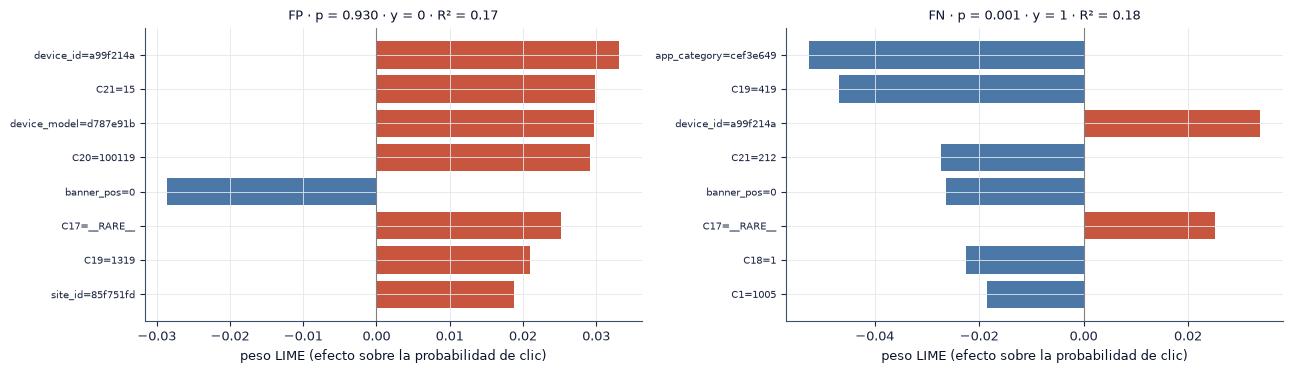

In [4]:
NS = max(C.LIME_NUM_SAMPLES)
def pesos(caso, kernel=0.75, ns=NS, semilla=0):
    r = lime[(lime["caso"] == caso) & (lime["kernel"] == kernel) & (lime["num_samples"] == ns) & (lime["semilla"] == semilla)].iloc[0]
    return pd.Series(r["pesos"]), r["r2"], r["pred_local"]

idx_fp = casos.index[casos["tipo"] == "FP"][0]
idx_fn = casos.index[casos["tipo"] == "FN"][0]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, i in zip(axes, [idx_fp, idx_fn]):
    w, r2, pl_ = pesos(i)
    w = w.reindex(w.abs().sort_values(ascending=False).index)[:8][::-1]
    labels = [f"{v}={casos.loc[i, 'x_' + v]}" for v in w.index]
    ax.barh(labels, w.values, color=[C.ACCENT if x > 0 else C.BAR for x in w.values])
    ax.axvline(0, c="gray", lw=0.8)
    ax.set_title(f"{casos.loc[i, 'tipo']} · p = {casos.loc[i, 'p']:.3f} · y = {int(casos.loc[i, 'y'])} · R² = {r2:.2f}", fontsize=9)
    ax.set_xlabel("peso LIME (efecto sobre la probabilidad de clic)"); ax.tick_params(axis="y", labelsize=7)
fig.tight_layout(); P.save(fig, "8_3_lime_casos"); plt.show()

## 8.4 Fidelidad y sensibilidad a la configuración

Calculamos el $R^2$ del modelo sustituto para los 20 casos, las 10 semillas y cada combinación de ancho del núcleo ($0.5$, $0.75$ y $1.5$ veces $\sqrt{p}$) y número de perturbaciones (1000 y 5000).

median   mean    std    min    max
kernel num_samples                                    
0.50   1000          0.195  0.194  0.026  0.117  0.285
       5000          0.175  0.167  0.029  0.091  0.227
0.75   1000          0.188  0.185  0.031  0.113  0.284
       5000          0.172  0.165  0.031  0.081  0.226
1.50   1000          0.185  0.182  0.034  0.101  0.284
       5000          0.171  0.163  0.032  0.078  0.226

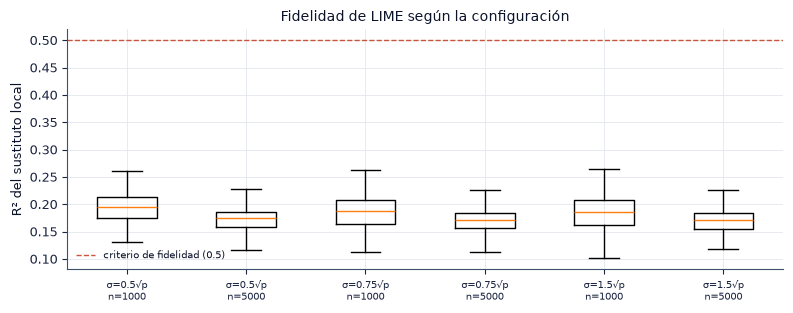

In [5]:
fid = lime.groupby(["kernel", "num_samples"])["r2"].agg(["median", "mean", "std", "min", "max"])
display(fid.round(3))
fig, ax = plt.subplots(figsize=(8, 3.2))
grupos = list(fid.index)
ax.boxplot([lime[(lime["kernel"] == k) & (lime["num_samples"] == n)]["r2"] for k, n in grupos], showfliers=False)
ax.set_xticks(range(1, len(grupos) + 1), [f"σ={k}√p\nn={n}" for k, n in grupos], fontsize=7)
ax.axhline(0.5, c=C.ACCENT, ls="--", lw=1, label="criterio de fidelidad (0.5)")
ax.set_ylabel("R² del sustituto local"); ax.set_title("Fidelidad de LIME según la configuración"); ax.legend(fontsize=7)
fig.tight_layout(); P.save(fig, "8_4_fidelidad"); plt.show()

## 8.5 Estabilidad

Para cada caso y configuración calculamos la similitud de Jaccard media entre los conjuntos de las 5 variables principales de las 10 repeticiones (45 pares).

num_samples,1000,5000
kernel,,
0.50,0.515,0.728
0.75,0.504,0.737
1.50,0.501,0.730


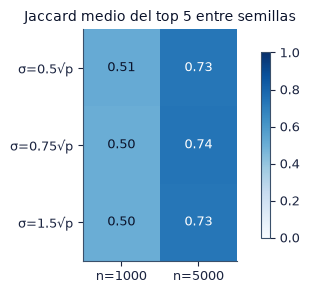

In [6]:
def top5(d):
    s = pd.Series(d)
    return set(s.abs().sort_values(ascending=False).index[:C.LIME_TOP_FEATURES])

est = (lime.assign(top=lime["pesos"].map(top5)).groupby(["caso", "tipo", "kernel", "num_samples"])["top"]
       .apply(lambda s: X.mean_pairwise_jaccard(list(s))).rename("jaccard").reset_index())
tab_est = est.pivot_table(index="kernel", columns="num_samples", values="jaccard", aggfunc="mean")
display(tab_est.round(3))
fig, ax = plt.subplots(figsize=(5, 3))
im = ax.imshow(tab_est.values, cmap="Blues", vmin=0, vmax=1); ax.grid(False)
ax.set_xticks(range(tab_est.shape[1]), [f"n={c}" for c in tab_est.columns]); ax.set_yticks(range(tab_est.shape[0]), [f"σ={k}√p" for k in tab_est.index])
for i in range(tab_est.shape[0]):
    for j in range(tab_est.shape[1]):
        ax.text(j, i, f"{tab_est.iat[i, j]:.2f}", ha="center", va="center", color="white" if tab_est.iat[i, j] > 0.6 else "#0B132B")
ax.set_title("Jaccard medio del top 5 entre semillas"); fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout(); P.save(fig, "8_5_estabilidad"); plt.show()

In [7]:
d_ = (0.75, NS)
r2_def = lime[(lime["kernel"] == d_[0]) & (lime["num_samples"] == d_[1])]["r2"].median()
j_def = tab_est.loc[d_[0], d_[1]]
mejor = tab_est.stack().idxmax()
R.findings(
    f"Con la configuración por defecto y {NS} perturbaciones, el $R^2$ mediano es {r2_def:.3f} y el Jaccard medio del top 5 es {j_def:.3f}. "
    f"La configuración más estable es σ = {mejor[0]}√p con {mejor[1]} perturbaciones (Jaccard {tab_est.loc[mejor]:.3f}). "
    f"Aumentar las perturbaciones de {min(C.LIME_NUM_SAMPLES)} a {max(C.LIME_NUM_SAMPLES)} cambia el Jaccard medio en "
    f"{(tab_est[max(C.LIME_NUM_SAMPLES)] - tab_est[min(C.LIME_NUM_SAMPLES)]).mean():+.3f}.",
    {"Criterio de P4": ("las explicaciones cumplen ambos criterios declarados (Jaccard ≥ 0.8 y R² ≥ 0.5)." if (j_def >= 0.8 and r2_def >= 0.5) else
                        "las explicaciones no cumplen los dos criterios declarados con la configuración por defecto: "
                        + ("son estables pero " if j_def >= 0.8 else "no son estables (Jaccard < 0.8) y ")
                        + ("fieles." if r2_def >= 0.5 else "el sustituto lineal explica menos de la mitad de la variación local (R² < 0.5).")),
     "Modelado": "la inestabilidad proviene del muestreo aleatorio de las perturbaciones: con pocas perturbaciones, variables con pesos parecidos intercambian su lugar en el top 5.",
     "Riesgos": "una explicación inestable puede cambiar de una ejecución a otra con la misma entrada; reportar una sola ejecución de LIME sin fijar la semilla no es reproducible."})

### Hallazgos y decisiones

Con la configuración por defecto y 5000 perturbaciones, el $R^2$ mediano es 0.172 y el Jaccard medio del top 5 es 0.737. La configuración más estable es σ = 0.75√p con 5000 perturbaciones (Jaccard 0.737). Aumentar las perturbaciones de 1000 a 5000 cambia el Jaccard medio en +0.225.

- **Criterio de P4:** las explicaciones no cumplen los dos criterios declarados con la configuración por defecto: no son estables (Jaccard < 0.8) y el sustituto lineal explica menos de la mitad de la variación local (R² < 0.5).
- **Modelado:** la inestabilidad proviene del muestreo aleatorio de las perturbaciones: con pocas perturbaciones, variables con pesos parecidos intercambian su lugar en el top 5.
- **Riesgos:** una explicación inestable puede cambiar de una ejecución a otra con la misma entrada; reportar una sola ejecución de LIME sin fijar la semilla no es reproducible.


## 8.6 Contraste con SHAP y con la importancia por permutación

**SHAP** asigna a cada variable su valor de Shapley: la contribución media de la variable a la predicción, promediada sobre todos los órdenes en que pueden agregarse las variables (Lundberg y Lee, 2017). Usamos el explicador por permutaciones de la librería `shap` en el mismo espacio interpretable, con 100 filas de entrenamiento como fondo. A diferencia de LIME, los valores de Shapley cumplen la propiedad de eficiencia: suman la diferencia entre la predicción del caso y la predicción media del fondo.

**Importancia por permutación.** Es una medida global: la caída del ROC AUC en validación cuando se permutan al azar los valores de una variable, promediada en 5 repeticiones.

Comparamos los métodos en dos niveles: por caso, con la correlación de Spearman entre $|w_j|$ de LIME (media de las 10 semillas, configuración por defecto) y $|\phi_j|$ de SHAP; y de forma global, con el orden de las variables según cada método.

Spearman |LIME| vs |SHAP|               Jaccard top 5 LIME vs SHAP        \
                          mean    min    max                       mean   min   
tipo                                                                            
FN                       0.456  0.368  0.575                      0.304  0.25   
FP                       0.398  0.100  0.586                      0.393  0.25   

             
        max  
tipo         
FN    0.429  
FP    0.429

,LIME (media |w|),SHAP (media |φ|),permutación (caída de AUC),rango LIME (media |w|),rango SHAP (media |φ|),rango permutación (caída de AUC)
banner_pos,0.0404,0.0262,0.0042,1,1,11
C21,0.0218,0.0245,0.0099,5,2,5
site_id,0.0183,0.0212,0.0119,6,3,2
app_category,0.0241,0.0149,0.0190,3,4,1
site_domain,0.0106,0.0146,0.0110,13,5,3
C16,0.0172,0.0130,0.0016,7,6,18
C17,0.0234,0.0127,0.0020,4,7,17
C19,0.0121,0.0117,0.0051,11,8,8
C18,0.0098,0.0079,0.0037,14,9,14
device_conn_type,0.0133,0.0077,0.0011,10,10,21


,LIME (media |w|),SHAP (media |φ|),permutación (caída de AUC)
LIME (media |w|),1.000,0.564,0.443
SHAP (media |φ|),0.564,1.000,0.570
permutación (caída de AUC),0.443,0.570,1.000


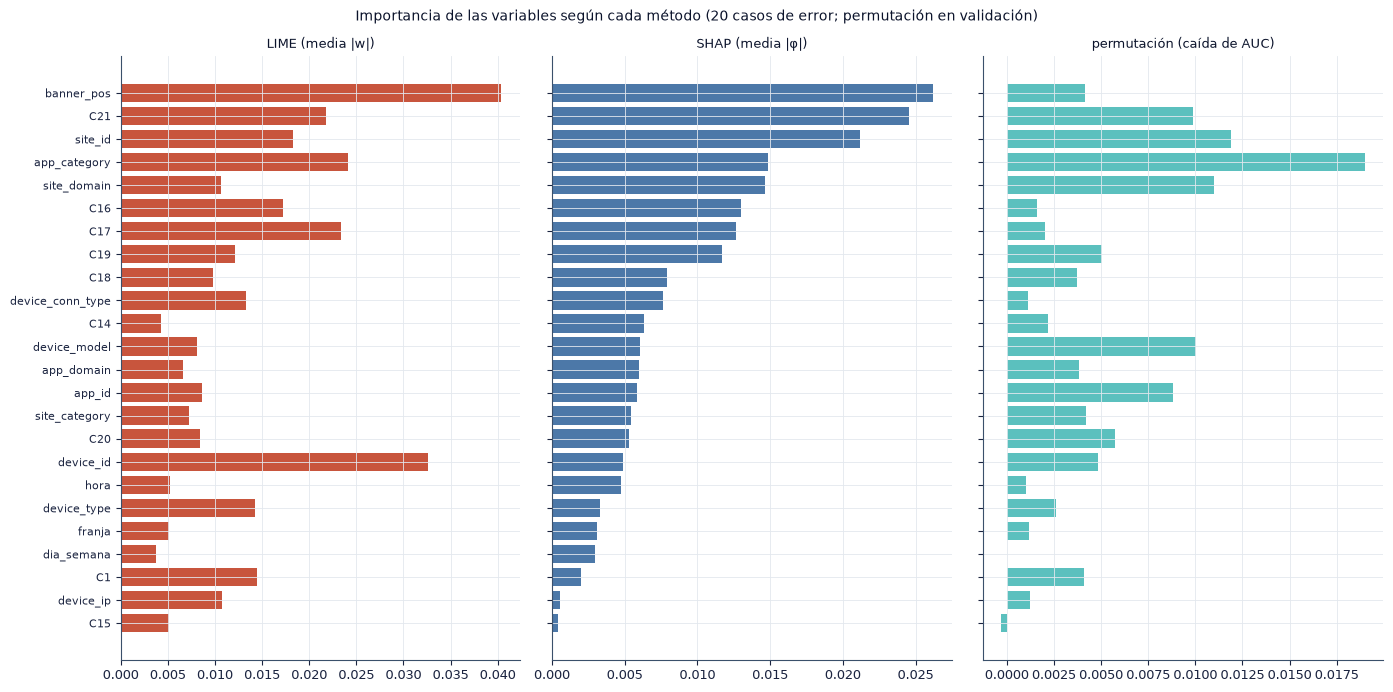

In [8]:
lime_def = lime[(lime["kernel"] == 0.75) & (lime["num_samples"] == NS)]
W = np.array([[np.mean([abs(p.get(c, 0.0)) for p in lime_def[lime_def["caso"] == i]["pesos"]]) for c in cols] for i in range(len(casos))])
S = np.abs(shap_v)
por_caso = pd.DataFrame({"caso": range(len(casos)), "tipo": casos["tipo"],
                         "Spearman |LIME| vs |SHAP|": [spearmanr(W[i], S[i]).statistic for i in range(len(casos))],
                         "Jaccard top 5 LIME vs SHAP": [X.jaccard(set(np.argsort(-W[i])[:5]), set(np.argsort(-S[i])[:5])) for i in range(len(casos))]})
display(por_caso.groupby("tipo")[["Spearman |LIME| vs |SHAP|", "Jaccard top 5 LIME vs SHAP"]].agg(["mean", "min", "max"]).round(3))

glob = pd.DataFrame({"LIME (media |w|)": W.mean(0), "SHAP (media |φ|)": S.mean(0)}, index=cols)
glob = glob.join(perm.set_index("variable")["caida_auc"].rename("permutación (caída de AUC)"))
rk = glob.rank(ascending=False).astype(int).add_prefix("rango ")
display(pd.concat([glob.round(4), rk], axis=1).sort_values("rango SHAP (media |φ|)").head(12))
corr = glob.corr(method="spearman")
display(corr.round(3))

fig, axes = plt.subplots(1, 3, figsize=(14, 7), sharey=True)
orden = glob["SHAP (media |φ|)"].sort_values().index
for ax, (col, cc) in zip(axes, [("LIME (media |w|)", C.ACCENT), ("SHAP (media |φ|)", C.BAR), ("permutación (caída de AUC)", "#5BC0BE")]):
    ax.barh(orden, glob.loc[orden, col], color=cc); ax.set_title(col, fontsize=9); ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Importancia de las variables según cada método (20 casos de error; permutación en validación)", fontsize=10)
fig.tight_layout(); P.save(fig, "8_6_lime_shap_permutacion"); plt.show()

In [9]:
rho_ls = corr.loc["LIME (media |w|)", "SHAP (media |φ|)"]
rho_sp = corr.loc["SHAP (media |φ|)", "permutación (caída de AUC)"]
top_lime = glob["LIME (media |w|)"].idxmax(); top_shap = glob["SHAP (media |φ|)"].idxmax(); top_perm = glob["permutación (caída de AUC)"].idxmax()
R.findings(
    f"Por caso, la correlación de Spearman media entre LIME y SHAP es {por_caso['Spearman |LIME| vs |SHAP|'].mean():.2f} y el Jaccard medio de "
    f"sus top 5 es {por_caso['Jaccard top 5 LIME vs SHAP'].mean():.2f}. En el agregado, el orden de LIME y el de SHAP tienen ρ = {rho_ls:.2f}, "
    f"y SHAP y la permutación ρ = {rho_sp:.2f}. La variable más importante es `{top_lime}` para LIME, `{top_shap}` para SHAP y `{top_perm}` "
    "para la permutación.",
    {"Coherencia": ("los métodos coinciden en las variables principales." if len({top_lime, top_shap, top_perm}) == 1 else
                    "los métodos no coinciden en la variable principal; la explicación depende del método elegido."),
     "Modelado": "LIME y SHAP explican casos individuales; la permutación mide el efecto global sobre el AUC. Una variable puede pesar mucho en los errores confiados y poco en el desempeño global.",
     "Riesgos": "SHAP con fondo independiente rompe las dependencias entre variables (por ejemplo, entre `site_id` y `site_domain`) y evalúa al modelo en combinaciones poco realistas; LIME tiene el mismo problema al muestrear cada variable por separado."})

### Hallazgos y decisiones

Por caso, la correlación de Spearman media entre LIME y SHAP es 0.43 y el Jaccard medio de sus top 5 es 0.35. En el agregado, el orden de LIME y el de SHAP tienen ρ = 0.56, y SHAP y la permutación ρ = 0.57. La variable más importante es `banner_pos` para LIME, `banner_pos` para SHAP y `app_category` para la permutación.

- **Coherencia:** los métodos no coinciden en la variable principal; la explicación depende del método elegido.
- **Modelado:** LIME y SHAP explican casos individuales; la permutación mide el efecto global sobre el AUC. Una variable puede pesar mucho en los errores confiados y poco en el desempeño global.
- **Riesgos:** SHAP con fondo independiente rompe las dependencias entre variables (por ejemplo, entre `site_id` y `site_domain`) y evalúa al modelo en combinaciones poco realistas; LIME tiene el mismo problema al muestrear cada variable por separado.
